# 07 · Custom YOLO heads and longer / larger RT-DETR training

Bonus 3 of the report (§5.3) and the late tuning runs (§4). All runs are scored on fold 0 (every 4th frame).

* `yolo_base`, `yolo_base_s1`, `yolo_base_r2` – YOLO11s, 1344 px, 12 epochs. Same configuration three times (`_s1` = other seed, `_r2` = repeat with seed 0 on a different machine), used as a noise estimate.
* `yolo_p2` / `yolo_p2_hinit` / `yolo_p2_hinit_r2` – extra stride-4 (P2) level; `hinit` copies the pretrained head weights into the matching levels. `_r2` is a repeat.
* `yolo_p2_nop5` – P2 head without the stride-32 level; `yolo_p3p4` – only strides 8 and 16.
* `rtdetr_s5_1536` – reference RT-DETR-l (12 epochs, 1536 px); `rtdetr_e24` – the same for 24 epochs; `rtdetr_1792` – 12 epochs at 1792 px (batch 2 instead of 3 to fit in T4 memory).

Validation predictions exist only for the `_r2` runs and the two new RT-DETR runs (older runs' prediction files are not in this checkout), so the error analysis and failure cases use those.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from hw2 import CLASSES
from hw2.analysis import load_run, metrics_table, error_breakdown, worst_frames, draw
from hw2.data import find_data_root, fold_frames, load_all, make_folds, subsample

sns.set_theme(style="whitegrid", context="notebook")
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
frames, boxes = load_all(find_data_root())
val = subsample(fold_frames(frames, make_folds(frames), 0), 4)   # the validation frames every run was scored on
vpath = val.set_index("key").path
vboxes = boxes[boxes.key.isin(set(val.key))]

In [2]:
def ultra_curve(r):
    h = pd.read_csv(f"../runs/{r}/train/results.csv"); h.columns = [c.strip() for c in h.columns]
    return h

def crop_window(gt, W, H, frac=0.45):
    g = gt[gt.ignore == 0]
    cx, cy = g.x + g.w / 2, g.y + g.h / 2
    w, h = int(W * frac), int(H * frac)
    best = max(((x0, y0) for x0 in np.linspace(0, W - w, 4).astype(int) for y0 in np.linspace(0, H - h, 4).astype(int)),
               key=lambda p: ((cx >= p[0]) & (cx < p[0] + w) & (cy >= p[1]) & (cy < p[1] + h)).sum())
    return best[0], best[1], best[0] + w, best[1] + h

def show_cases(runs, cases, fname, thr=0.3):
    """One row per case, one column per run: green = ground truth, grey = ignored region, red = detections."""
    fig, axes = plt.subplots(len(cases), len(runs), figsize=(6.5 * len(runs), 4.2 * len(cases)), squeeze=False)
    preds = {r: load_run(r)["val_preds"] for r in runs}
    for i, (key, why) in enumerate(cases):
        gt = vboxes[vboxes.key == key]
        fr = val.set_index("key").loc[key]
        crop = crop_window(gt, int(fr.width), int(fr.height))
        for j, r in enumerate(runs):
            axes[i, j].imshow(draw(vpath[key], preds[r][preds[r].key == key], gt, thr, crop))
            axes[i, j].set_title(f"{r}: {why}", fontsize=9); axes[i, j].axis("off")
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=110); plt.show()

## Metrics and run-to-run noise

In [3]:
Y = ['yolo_base', 'yolo_base_s1', 'yolo_base_r2', 'yolo_p2', 'yolo_p2_hinit', 'yolo_p2_hinit_r2', 'yolo_p2_nop5', 'yolo_p3p4']
R = ['rtdetr_s5_1536', 'rtdetr_e24', 'rtdetr_1792']
t = metrics_table(Y + R).round(4); t

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_min
run,,,,,,,,,
yolo_base,0.2449,0.4427,0.2407,0.0797,0.1736,0.4004,0.3657,74.91,29.2
yolo_base_s1,0.2294,0.4123,0.2239,0.0769,0.1644,0.3859,0.3516,71.27,31.7
yolo_base_r2,0.2514,0.4551,0.2465,0.0787,0.1842,0.4220,0.3736,74.70,28.2
yolo_p2,0.2178,0.4301,0.1953,0.0756,0.1657,0.3524,0.3929,50.85,51.7
yolo_p2_hinit,0.2446,0.4656,0.2240,0.0797,0.1837,0.3893,0.4021,54.13,52.9
yolo_p2_hinit_r2,0.2269,0.4308,0.2088,0.0796,0.1548,0.3818,0.3844,54.55,47.5
yolo_p2_nop5,0.2210,0.4359,0.1966,0.0763,0.1674,0.3551,0.3775,56.85,53.0
yolo_p3p4,0.2308,0.4274,0.2173,0.0733,0.1642,0.3802,0.3601,74.51,31.4
rtdetr_s5_1536,0.3096,0.5510,0.2993,0.1024,0.2329,0.4909,0.4729,10.24,147.1


In [4]:
noise = pd.DataFrame({
    "runs": ["yolo_base x3", "yolo_p2_hinit x2"],
    "mAP values": [t.loc[['yolo_base', 'yolo_base_s1', 'yolo_base_r2'], 'mAP'].tolist(), t.loc[['yolo_p2_hinit', 'yolo_p2_hinit_r2'], 'mAP'].tolist()],
    "range": [np.ptp(t.loc[['yolo_base', 'yolo_base_s1', 'yolo_base_r2'], 'mAP']), np.ptp(t.loc[['yolo_p2_hinit', 'yolo_p2_hinit_r2'], 'mAP'])]})
noise

,runs,mAP values,range
0,yolo_base x3,"[0.2449, 0.2294, 0.2514]",0.0220
1,yolo_p2_hinit x2,"[0.2446, 0.2269]",0.0177


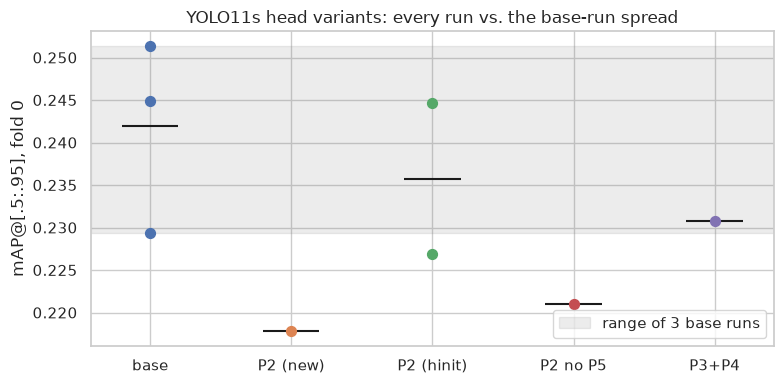

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
groups = {'base': ['yolo_base', 'yolo_base_s1', 'yolo_base_r2'], 'P2 (new)': ['yolo_p2'], 'P2 (hinit)': ['yolo_p2_hinit', 'yolo_p2_hinit_r2'],
          'P2 no P5': ['yolo_p2_nop5'], 'P3+P4': ['yolo_p3p4']}
for i, (g, rs) in enumerate(groups.items()):
    v = t.loc[rs, 'mAP']
    ax.scatter([i] * len(v), v, s=50, zorder=3); ax.hlines(v.mean(), i - 0.2, i + 0.2, color='k')
ax.axhspan(t.loc[groups['base'], 'mAP'].min(), t.loc[groups['base'], 'mAP'].max(), color='grey', alpha=0.15, label='range of 3 base runs')
ax.set_xticks(range(len(groups))); ax.set_xticklabels(groups); ax.set_ylabel('mAP@[.5:.95], fold 0'); ax.legend()
ax.set_title('YOLO11s head variants: every run vs. the base-run spread'); fig.tight_layout(); fig.savefig(IMG / 'arch_noise.png', dpi=140); plt.show()

## AP by object size and class

In [6]:
sz = t.loc[Y, ['AP_small', 'AP_medium', 'AP_large', 'AR500']]; sz

,AP_small,AP_medium,AP_large,AR500
run,,,,
yolo_base,0.0797,0.1736,0.4004,0.3657
yolo_base_s1,0.0769,0.1644,0.3859,0.3516
yolo_base_r2,0.0787,0.1842,0.4220,0.3736
yolo_p2,0.0756,0.1657,0.3524,0.3929
yolo_p2_hinit,0.0797,0.1837,0.3893,0.4021
yolo_p2_hinit_r2,0.0796,0.1548,0.3818,0.3844
yolo_p2_nop5,0.0763,0.1674,0.3551,0.3775
yolo_p3p4,0.0733,0.1642,0.3802,0.3601


In [7]:
pc = pd.DataFrame({r: {c: json.load(open(f"../runs/{r}/metrics.json"))[f"AP_{c}"] for c in CLASSES} for r in Y + R}).T.round(3); pc

,person,bicycle,car,van,truck,tricycle,bus,motor
yolo_base,0.218,0.069,0.500,0.174,0.172,0.269,0.458,0.107
yolo_base_s1,0.204,0.057,0.508,0.160,0.111,0.223,0.466,0.112
yolo_base_r2,0.221,0.078,0.503,0.191,0.167,0.262,0.482,0.114
yolo_p2,0.200,0.074,0.487,0.170,0.112,0.256,0.351,0.106
yolo_p2_hinit,0.206,0.076,0.493,0.153,0.166,0.274,0.480,0.120
yolo_p2_hinit_r2,0.203,0.067,0.490,0.161,0.087,0.264,0.434,0.119
yolo_p2_nop5,0.210,0.079,0.492,0.153,0.146,0.253,0.333,0.115
yolo_p3p4,0.221,0.070,0.498,0.164,0.154,0.239,0.396,0.113
rtdetr_s5_1536,0.238,0.110,0.528,0.252,0.303,0.320,0.602,0.130
rtdetr_e24,0.222,0.090,0.513,0.227,0.207,0.279,0.555,0.118


## Error breakdown (runs with predictions)

Simplified TIDE-style counts at score ≥ 0.3 (see `hw2.analysis.error_breakdown`).

In [8]:
P = ['yolo_base_r2', 'yolo_p2_hinit_r2', 'rtdetr_e24', 'rtdetr_1792']
bd = pd.DataFrame({r: error_breakdown(load_run(r)['val_preds'], vboxes, val.key, score_thr=0.3) for r in P}).T; bd

,tp,duplicate,cls,loc,ignored,background,missed_small,missed_medium,missed_large,recall_small,recall_medium,recall_large
yolo_base_r2,43586.0,380.0,5233.0,3371.0,10317.0,6370.0,8497.0,15074.0,1374.0,0.329,0.664,0.876
yolo_p2_hinit_r2,43604.0,722.0,5593.0,4344.0,11958.0,7006.0,8512.0,15095.0,1320.0,0.328,0.663,0.880
rtdetr_e24,49646.0,2450.0,7627.0,7071.0,28335.0,16561.0,7423.0,10538.0,924.0,0.414,0.765,0.916
rtdetr_1792,52082.0,4898.0,8987.0,9627.0,35592.0,21588.0,6108.0,9507.0,834.0,0.518,0.788,0.924


In [9]:
# Recall of small objects as a function of the score threshold: does the P2 head find more small objects at all?
def recall_small(r, thrs=(0.05, 0.1, 0.2, 0.3, 0.5)):
    p = load_run(r)['val_preds']
    return {thr: error_breakdown(p, vboxes, val.key, score_thr=thr)['recall_small'] for thr in thrs}
rs = pd.DataFrame({r: recall_small(r) for r in ['yolo_base_r2', 'yolo_p2_hinit_r2']}).T; rs

,0.05,0.10,0.20,0.30,0.50
yolo_base_r2,0.465,0.432,0.379,0.329,0.182
yolo_p2_hinit_r2,0.477,0.438,0.382,0.328,0.191


## RT-DETR: longer training and higher resolution

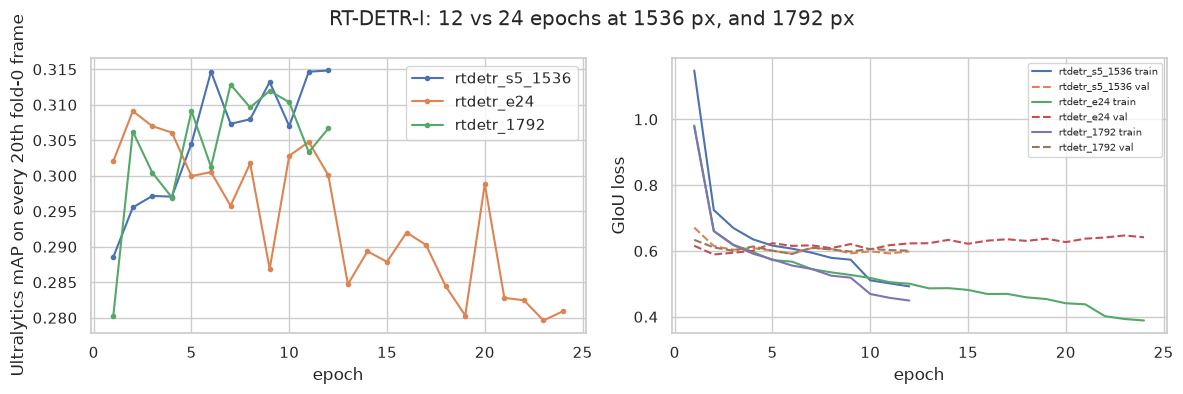

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for r in R:
    h = ultra_curve(r)
    axes[0].plot(h.epoch, h['metrics/mAP50-95(B)'], marker='o', ms=3, label=r)
    axes[1].plot(h.epoch, h['train/giou_loss'], label=f'{r} train'); axes[1].plot(h.epoch, h['val/giou_loss'], '--', label=f'{r} val')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('Ultralytics mAP on every 20th fold-0 frame'); axes[0].legend()
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('GIoU loss'); axes[1].legend(fontsize=7)
fig.suptitle('RT-DETR-l: 12 vs 24 epochs at 1536 px, and 1792 px'); fig.tight_layout(); fig.savefig(IMG / 'rtdetr_epochs.png', dpi=140); plt.show()

## Failure cases

Cases are picked on `yolo_base_r2` (most missed small objects, most class confusions, most background false alarms among 150 random frames), then the same crops are shown for the P2 head.

In [11]:
w = worst_frames(load_run('yolo_base_r2')['val_preds'], vboxes, val.key, n_sample=150)
miss = w.sort_values('missed_small', ascending=False).index[0]
conf = w[w.index != miss].sort_values('cls', ascending=False).index[0]
fp = w[~w.index.isin([miss, conf])].sort_values('background', ascending=False).index[0]
cases = [(miss, 'most missed small objects'), (conf, 'most class confusions'), (fp, 'most background false alarms')]
w.loc[[c for c, _ in cases]]

,tp,duplicate,cls,loc,ignored,background,missed_small,missed_medium,missed_large,recall_small,recall_medium,recall_large,n_gt
key,,,,,,,,,,,,,
uav0000124_00944_v_0000185,77,2,3,5,4,1,29,26,0,0.094,0.698,1.0,132
uav0000288_00001_v_0000125,29,0,21,5,0,9,11,19,0,0.450,0.441,1.0,59
uav0000140_01590_v_0000189,42,0,1,2,72,34,0,1,0,1.000,0.962,1.0,43


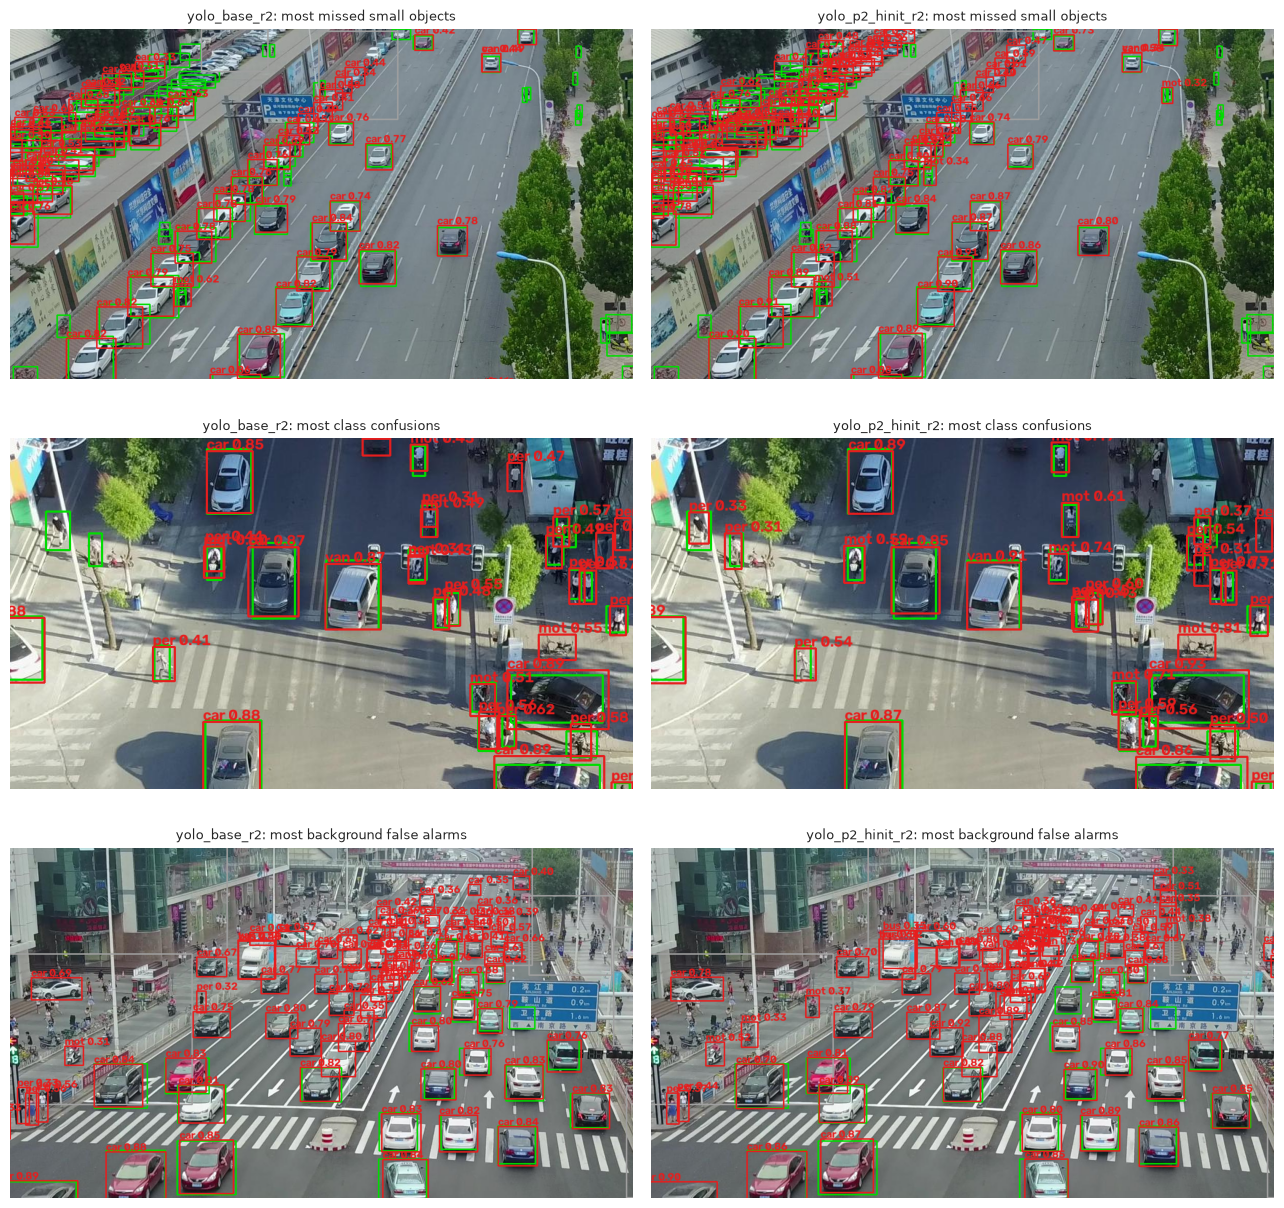

In [12]:
show_cases(['yolo_base_r2', 'yolo_p2_hinit_r2'], cases, 'fail_arch.png')

In [13]:
# Same frames scored for the P2 head: does it miss fewer small objects where the base head fails most?
w2 = worst_frames(load_run('yolo_p2_hinit_r2')['val_preds'], vboxes, val.key, n_sample=150)
cmp = pd.DataFrame({'base missed_small': w.missed_small, 'P2 missed_small': w2.missed_small, 'n_gt': w.n_gt})
print('frames where P2 misses fewer / more small objects:', (cmp['P2 missed_small'] < cmp['base missed_small']).sum(),
      '/', (cmp['P2 missed_small'] > cmp['base missed_small']).sum(), 'of', len(cmp))
cmp[['base missed_small', 'P2 missed_small']].sum()

frames where P2 misses fewer / more small objects: 25 / 29 of 150


base missed_small    933
P2 missed_small      939
dtype: int64

## Summary

* **Noise.** Three identical-configuration YOLO11s runs span 0.2294-0.2514 (range 0.022), two `P2-hinit` runs 0.2269-0.2446 (0.018). Every head variant lies inside or below the reference range, so none of them is an improvement.
* **The P2 head does not find more small objects.** AP_small 0.0796 vs 0.0787 for the repeated runs; small-object recall is the same at every score threshold (0.329 vs 0.328 at 0.3). On 150 random frames P2 misses fewer small objects in 25 frames and more in 29 (933 vs 939 misses).
* **Failure cases** are the same clips as for the other families (§3 of the report): distant parked cars in `uav0000124_00944`, vehicle/person confusions in `uav0000288_00001`. The P2 head fails on them in the same way.
* **RT-DETR, 24 epochs overfits.** Training GIoU loss falls from 0.50 to 0.39 between epochs 12 and 24 while validation GIoU loss rises from 0.62 to 0.64; final mAP 0.2755 vs 0.3096 for 12 epochs.
* **RT-DETR at 1792 px** (batch 2): 0.3035 vs 0.3096, within noise, at 70% of the speed.